<a href="https://colab.research.google.com/github/Joel-Nadar/sc-model/blob/main/SC_MODEL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First 5 rows:
    person_age  person_income person_home_ownership  person_emp_length  \
0          22          59000                  RENT              123.0   
1          21           9600                   OWN                5.0   
2          25           9600              MORTGAGE                1.0   
3          23          65500                  RENT                4.0   
4          24          54400                  RENT                8.0   

  loan_intent loan_grade  loan_amnt  loan_int_rate  loan_status  \
0    PERSONAL          D      35000          16.02            1   
1   EDUCATION          B       1000          11.14            0   
2     MEDICAL          C       5500          12.87            1   
3     MEDICAL          C      35000          15.23            1   
4     MEDICAL          C      35000          14.27            1   

   loan_percent_income cb_person_default_on_file  cb_person_cred_hist_length  
0                 0.59                         Y                

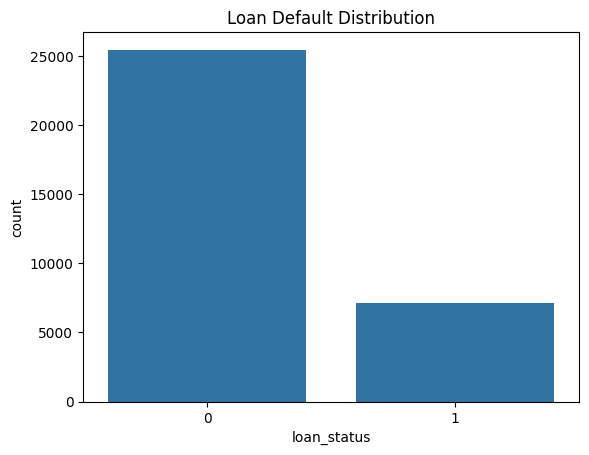


Missing values after cleaning:
 person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64

Processed train shape: (22909, 26)
Processed test shape: (5728, 26)

Class weights: {np.int64(0): np.float64(0.6382403744358388), np.int64(1): np.float64(2.3084441757355907)}


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,841 (15.00 KB)

 Trainable params: 3,841 (15.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
573/573 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.7626 - loss: 0.4872 - val_accuracy: 0.8282 - val_loss: 0.3979
Epoch 2/50
573/573 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8351 - loss: 0.4150 - val_accuracy: 0.8518 - val_loss: 0.3655
Epoch 3/50
573/573 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8529 - loss: 0.3911 - val_accuracy: 0.8675 - val_loss: 0.3495
Epoch 4/50
573/573 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8661 - loss: 0.3788 - val_accuracy: 0.8734 - val_loss: 0.3393
Epoch 5/50
573/573 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8708 - loss: 0.3724 - val_accuracy: 0.8804 - val_loss: 0.3339
Epoch 6/50
573/573 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8780 - loss: 0.3631 - val_accuracy: 0.8907 - val_loss: 0.3169
Epoch 7/50
573/573 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8827 - loss: 0.3542 - val_accuracy: 0.8893 - val_loss: 0.3181
Epoch 8/50
573/573 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8867 - loss: 0.3494 - val_accuracy: 0.

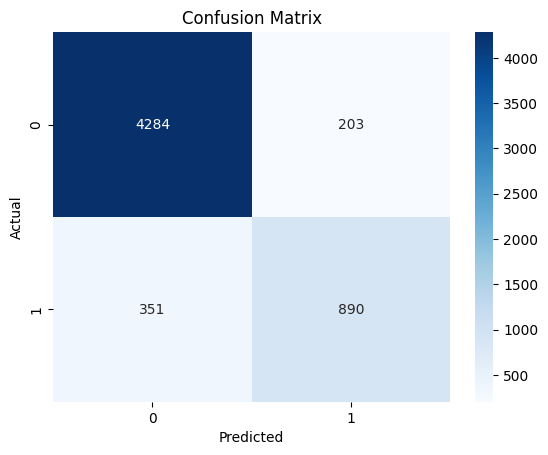

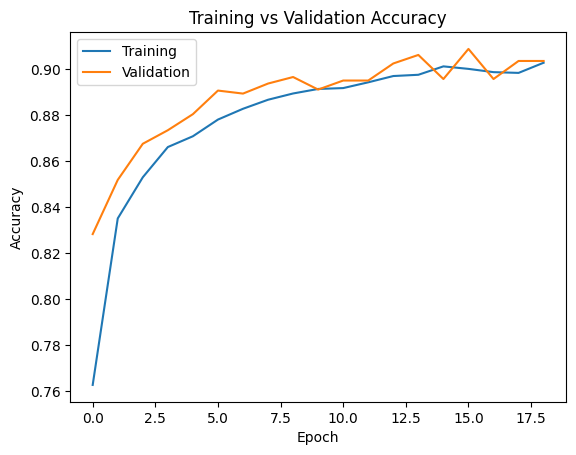

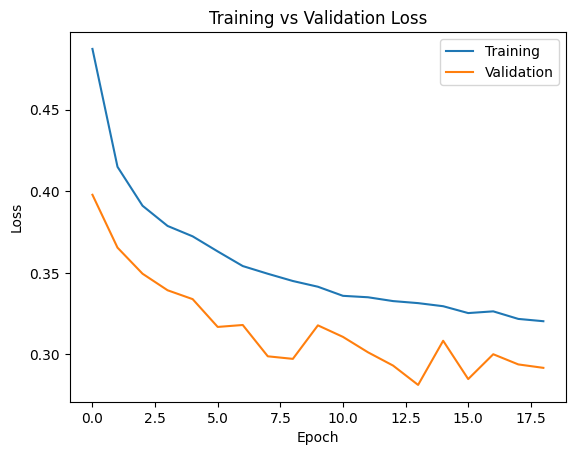

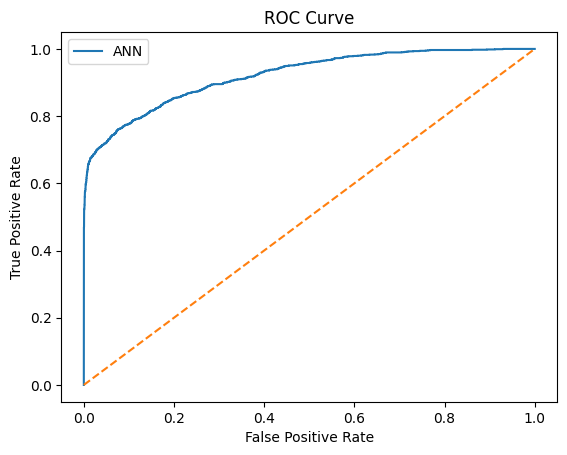

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step

--- Sample Real-Time Prediction ---
Default Probability: 20.48%
Risk Category: Low Risk

Model saved as loan_default_ann.keras


In [2]:
"""
ANN-Based Loan Default Risk Prediction
========================================
Predicts whether a loan applicant is likely to default using an
Artificial Neural Network (ANN) built with TensorFlow/Keras.

Dataset expected: credit_risk_dataset.csv
Target column:    loan_status   (0 = Non-default, 1 = Default)

Run:
    pip install tensorflow pandas numpy scikit-learn matplotlib seaborn
    python loan_default_ann.py
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


# ---------------------------------------------------------------
# 1. Load dataset
# ---------------------------------------------------------------
df = pd.read_csv("credit_risk_dataset.csv")

print("First 5 rows:\n", df.head())
print("\nShape:", df.shape)
print("\nColumns:", list(df.columns))
print("\nMissing values per column:\n", df.isnull().sum())


# ---------------------------------------------------------------
# 2. Explore dataset
# ---------------------------------------------------------------
print("\nInfo:")
print(df.info())
print("\nDescribe:\n", df.describe())
print("\nTarget distribution:\n", df["loan_status"].value_counts())

sns.countplot(x="loan_status", data=df)
plt.title("Loan Default Distribution")
plt.show()


# ---------------------------------------------------------------
# 3. Handle missing values (simple approach: drop them)
# ---------------------------------------------------------------
df = df.dropna()
print("\nMissing values after cleaning:\n", df.isnull().sum())


# ---------------------------------------------------------------
# 4. Separate features (X) and target (y)
# ---------------------------------------------------------------
X = df.drop("loan_status", axis=1)
y = df["loan_status"]


# ---------------------------------------------------------------
# 5. Define numerical and categorical columns
# ---------------------------------------------------------------
numeric_features = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length",
]

categorical_features = [
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
    "cb_person_default_on_file",
]


# ---------------------------------------------------------------
# 6. Preprocessing pipeline
#    - StandardScaler for numeric columns  -> z = (x - mean) / std
#    - OneHotEncoder for categorical columns -> text becomes 0/1 columns
# ---------------------------------------------------------------
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)


# ---------------------------------------------------------------
# 7. Train / test split (80% train, 20% test, stratified on target
#    since default datasets are usually imbalanced)
# ---------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


# ---------------------------------------------------------------
# 8. Fit preprocessing on train data, apply to both train & test
# ---------------------------------------------------------------
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

# Newer sklearn versions may already return a dense NumPy array instead of
# a sparse matrix, so only call .toarray() when it's actually sparse.
if hasattr(X_train, "toarray"):
    X_train = X_train.toarray()
if hasattr(X_test, "toarray"):
    X_test = X_test.toarray()

print("\nProcessed train shape:", X_train.shape)
print("Processed test shape:", X_test.shape)


# ---------------------------------------------------------------
# 9. Handle class imbalance (compute class weights)
# ---------------------------------------------------------------
classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weights = dict(zip(classes, weights))
print("\nClass weights:", class_weights)


# ---------------------------------------------------------------
# 10. Build the ANN
#     Input -> Dense(64, ReLU) -> Dropout(0.3)
#           -> Dense(32, ReLU) -> Dropout(0.2)
#           -> Dense(1, Sigmoid)
# ---------------------------------------------------------------
model = Sequential()
model.add(Dense(64, activation="relu", input_shape=(X_train.shape[1],)))
model.add(Dropout(0.3))
model.add(Dense(32, activation="relu"))
model.add(Dropout(0.2))
model.add(Dense(1, activation="sigmoid"))

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()


# ---------------------------------------------------------------
# 11. Train with early stopping
# ---------------------------------------------------------------
early_stopping = EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1,
)


# ---------------------------------------------------------------
# 12. Predict on test data
# ---------------------------------------------------------------
y_probability = model.predict(X_test)
y_pred = (y_probability >= 0.5).astype(int)


# ---------------------------------------------------------------
# 13. Evaluation metrics
# ---------------------------------------------------------------
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_probability)

print("\n--- Evaluation ---")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("ROC-AUC  :", auc)

print("\nClassification Report:\n", classification_report(y_test, y_pred))


# ---------------------------------------------------------------
# 14. Confusion matrix
# ---------------------------------------------------------------
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


# ---------------------------------------------------------------
# 15. Training vs validation accuracy / loss curves
# ---------------------------------------------------------------
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend(["Training", "Validation"])
plt.show()

plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend(["Training", "Validation"])
plt.show()


# ---------------------------------------------------------------
# 16. ROC curve
# ---------------------------------------------------------------
fpr, tpr, thresholds = roc_curve(y_test, y_probability)
plt.plot(fpr, tpr, label="ANN")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


# ---------------------------------------------------------------
# 17. Real-time prediction on a new customer
# ---------------------------------------------------------------
def predict_risk(customer_dict):
    """
    Takes a dict of a single customer's details, runs it through the
    same preprocessing pipeline and trained model, and returns the
    default probability plus a risk category.
    """
    new_customer = pd.DataFrame(customer_dict)
    processed = preprocessor.transform(new_customer)
    if hasattr(processed, "toarray"):
        processed = processed.toarray()

    probability = model.predict(processed)[0][0]

    if probability < 0.30:
        risk = "Low Risk"
    elif probability < 0.60:
        risk = "Medium Risk"
    else:
        risk = "High Risk"

    return probability, risk


example_customer = {
    "person_age": [28],
    "person_income": [60000],
    "person_home_ownership": ["RENT"],
    "person_emp_length": [4],
    "loan_intent": ["PERSONAL"],
    "loan_grade": ["B"],
    "loan_amnt": [10000],
    "loan_int_rate": [11.5],
    "loan_percent_income": [0.17],
    "cb_person_default_on_file": ["N"],
    "cb_person_cred_hist_length": [5],
}

probability, risk = predict_risk(example_customer)
print("\n--- Sample Real-Time Prediction ---")
print(f"Default Probability: {probability:.2%}")
print(f"Risk Category: {risk}")


# ---------------------------------------------------------------
# 18. Save the trained model (optional, useful for a Streamlit app)
# ---------------------------------------------------------------
model.save("loan_default_ann.keras")
print("\nModel saved as loan_default_ann.keras")